In [44]:
#exercicio 1

import numpy as np

#Definindo a função de densidade
def f(x):
    if x >= 0 and x <= 1:
        return 20 * x * (1-x)**3
    else:
        return 0

#1 obtendo aproximação do máximo

malha = np.linspace(0, 1, 1000)
valores_f = []

for x in malha:
    valores_f.append(f(x))

M = np.max(valores_f)
print(f"O valor máximo aproximado de f(x) é M ={M: .4f}")

#1.1 Gerando uma amostra pelo método aceitação-rejeição

n = 1000

amostra = []

tentativas_observadas = []

for i in range(n):
    tentativas = 0
    while True:
        tentativas += 1

        y = np.random.uniform(0,1)

        u = np.random.uniform(0,1)

        if u <= f(y) / M:
            amostra.append(y)
            break

            
    tentativas_observadas.append(tentativas)

O valor máximo aproximado de f(x) é M = 2.1094


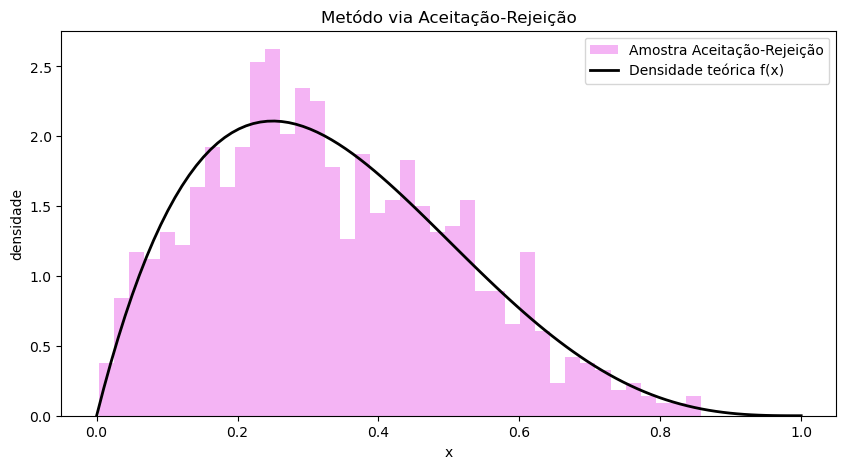

In [45]:
#2 fazendo um gráfico contendo a densidade teórica f(x) e o histograma normalizado da amostra gerada

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(amostra, bins=40, density=True, alpha=0.6, color='violet', 
         label='Amostra Aceitação-Rejeição')

x_teorico = np.linspace(0, 1, 100)
y_teorico = []
for x in x_teorico:
    y_teorico.append(f(x))

plt.plot(x_teorico, y_teorico, color='black', linewidth=2, 
         label='Densidade teórica f(x)')

plt.title("Metódo via Aceitação-Rejeição")
plt.xlabel("x")
plt.ylabel("densidade")
plt.legend()
plt.show()


In [46]:
#3.a) Determinando teoricamente a probabilidade de aceitação do método AR

probabilidade_aceitacao = 1/M
print(f"A probabilidade de aceitação do metódo AR é:{probabilidade_aceitacao: .4f}")

A probabilidade de aceitação do metódo AR é: 0.4741


In [47]:
#3.b) Determinando o número esperado de tentativas até a primeira aceitação

esperanca_tentativas = 1/ probabilidade_aceitacao
print(f"o número esperado de tentativas até a primeira aceitação é:{esperanca_tentativas: .4f}")

o número esperado de tentativas até a primeira aceitação é: 2.1094


In [48]:
#3.c) Comparando a média empírica do número de tentativas com o valor esperado teoricamente

media_empirica_tentativas = np.mean(tentativas_observadas)
print(f"""a média empírica das tentativas é: {media_empirica_tentativas:.4f} 
e o número esperado de tentativas até a primeira aceitação é:{esperanca_tentativas: .4f}""")

a média empírica das tentativas é: 2.1020 
e o número esperado de tentativas até a primeira aceitação é: 2.1094


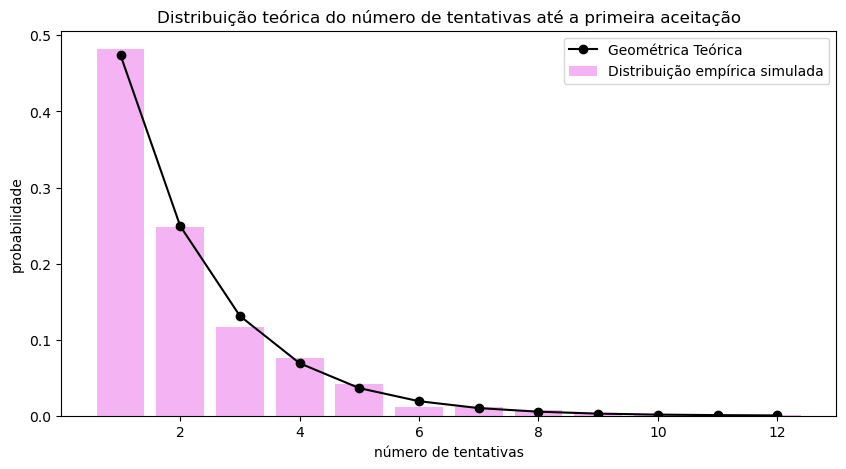

In [49]:
#3.d) 

plt.figure(figsize=(10, 5))

valores, contagens = np.unique(tentativas_observadas, return_counts=True)
frequencias = contagens/n

plt.bar(valores, frequencias, alpha=0.6, color='violet', label='Distribuição empírica simulada')

valores_k = range(1, max(valores) + 1)
probabilidade_teorica = []
for k in valores_k:
    probabilidade = ((1 - probabilidade_aceitacao)**(k-1)) * probabilidade_aceitacao
    probabilidade_teorica.append(probabilidade)

plt.plot(valores_k, probabilidade_teorica, 'o-', label='Geométrica Teórica', color='black')

plt.title("Distribuição teórica do número de tentativas até a primeira aceitação")
plt.xlabel("número de tentativas")
plt.ylabel("probabilidade")
plt.legend()
plt.show()